<Axes: >

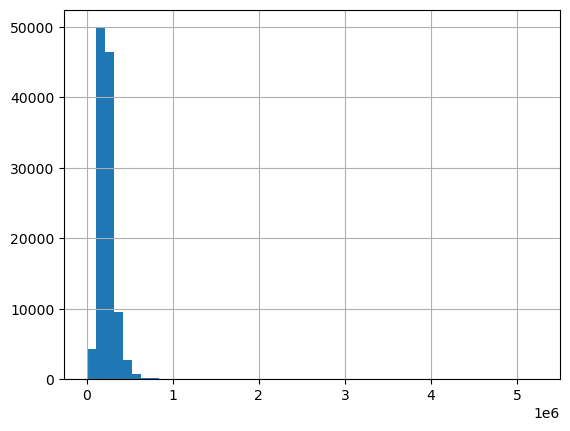

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = r"c:\Users\Jaconiah\Documents\Projek\spotify-music-recommender"
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
DATASET_FILE = os.path.join(RAW_DIR, "spotify_tracks.csv")

df = pd.read_csv(DATASET_FILE)


df.describe()
df['duration_ms'].hist(bins=50)

In [2]:
df.sort_values('duration_ms', ascending=False).head(10)
df.sort_values('duration_ms', ascending=True).head(10)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.5830,...,-9.460,0,0.0605,0.690,0.00396,0.0747,0.734,138.391,4,k-pop
59310,59310,6hsyfegVY5yklJneM40mWi,Leila Bela,Angra Manyu,The Exorsism Begins...,0,8586,False,0.000,0.0400,...,-29.714,0,0.0000,0.928,0.95600,0.1150,0.000,0.000,0,iranian
59812,59812,38Ogh3rsHba83kXx13gbKs,Leila Bela,Angra Manyu,V-4,0,13386,False,0.000,0.2240,...,-22.196,1,0.0000,0.970,0.00000,0.9070,0.000,0.000,0,iranian
59775,59775,1HVjSh7scH1PaPiLjy2LEu,Leila Bela;Leila's Opera Class,Angra Manyu,Screams for a Finale! (feat. Leila's Opera Class),0,15800,False,0.251,0.5080,...,-10.564,0,0.3160,0.969,0.99900,0.9520,0.000,184.051,3,iranian
16856,16856,5YKCM3jbJ8lqUXUwfU7KwZ,Wolfgang Amadeus Mozart;Ingrid Haebler,Mozart: The Complete Piano Sonatas,"Andante in C Major, K. 1a",0,17453,False,0.467,0.0301,...,-28.518,0,0.0428,0.995,0.90000,0.1240,0.000,84.375,4,classical
39233,39233,1T5QvLF9lO4HO3OZQbaX9p,Robert Schumann;Pavel Nersessian,"Schumann, Poulenc & Others: Piano Works (Live ...","Carnaval, Op. 9: No. 20, Pause (Live in Japan,...",0,17826,False,0.372,0.2780,...,-16.882,1,0.0370,0.985,0.92100,0.1640,0.912,89.032,1,german
16288,16288,1T5QvLF9lO4HO3OZQbaX9p,Robert Schumann;Pavel Nersessian,"Schumann, Poulenc & Others: Piano Works (Live ...","Carnaval, Op. 9: No. 20, Pause (Live in Japan,...",0,17826,False,0.372,0.2780,...,-16.882,1,0.0370,0.985,0.92100,0.1640,0.912,89.032,1,classical
59306,59306,3qSaeaXmtOuzkqe7DKgoiM,Leila Bela,Angra Manyu,V-7,0,21120,False,0.229,0.0577,...,-27.960,0,0.1960,0.626,0.93100,0.1080,0.253,172.897,4,iranian
59609,59609,1oVrTBrCsM2eTE1G50yxY9,Leila Bela,Angra Manyu,Shatter,0,21240,False,0.424,0.8690,...,-8.168,0,0.0728,0.707,0.08930,0.1170,0.000,135.107,4,iranian
11398,11398,1egJZfc8JBT2blFQ4clPKe,Benjamin Britten;Steven Isserlis,October Classical Playlist,"Cello Suite No. 3, Op. 87: IX. Passacaglia (Ex...",0,22266,False,0.335,0.0593,...,-26.365,0,0.0430,0.992,0.86900,0.1160,0.195,77.266,5,british


In [6]:

print(df.isnull().sum())

print("")
duplicates = df.duplicated(subset=['track_id']).sum()
print(f"Jumlah duplikasi track_id: {duplicates}")

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Jumlah duplikasi track_id: 24259


In [8]:
# Menghitung total nilai null di setiap kolom
print(df.isnull().sum())

# Menampilkan persentase null agar lebih informatif
null_percentage = (df.isnull().sum() / len(df)) * 100
print("\nPersentase Null per Kolom:")
print(null_percentage[null_percentage > 0])

# 1. Menampilkan baris yang mengandung null di KOLOM MANAPUN
rows_with_null = df[df.isnull().any(axis=1)]
print(f"Total baris dengan null: {len(rows_with_null)}")
display(rows_with_null.head())  # Tampilkan 5 baris pertama

# 2. Menampilkan baris yang null di KOLOM SPESIFIK (misal: 'artists' atau 'track_name')
null_artists = df[df['artists'].isnull()]
display(null_artists)

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Persentase Null per Kolom:
artists       0.000877
album_name    0.000877
track_name    0.000877
dtype: float64
Total baris dengan null: 1


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [ ]:
# Menampilkan semua baris yang duplikat persis
# keep=False artinya tampilkan SEMUA kemunculan (baik asli maupun salinannya)
duplicates_all = df[df.duplicated(keep=False)]
print(f"Total baris duplikat sempurna: {len(duplicates_all)}")
display(duplicates_all.sort_values(by='track_id'))

# Menampilkan semua baris dengan track_id yang berulang
duplicate_tracks = df[df.duplicated(subset=['track_id'], keep=False)]
print(f"Total lagu yang terduplikasi berdasarkan track_id: {len(duplicate_tracks)}")

# Tampilkan data yang diurutkan berdasarkan track_id agar terlihat perbandingannya
# display(duplicate_tracks[['track_id', 'artists', 'track_name', 'album_name', 'track_genre']].sort_values(by='track_id').head(10))

display(duplicate_tracks.sort_values(by='track_id'))

duplicate_tracks.to_csv('spotify_duplicates.csv', index=False)

Total baris duplikat sempurna: 0


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


Total lagu yang terduplikasi berdasarkan track_id: 40900


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.316000,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.316000,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.019400,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.019400,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.001210,0.000000,0.0995,0.236,148.033,4,rock
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72679,72679,7zv2vmZq8OjS54BxFzI2wM,Attila,Soundtrack to a Party (Bonus),Lets Start the Party,25,125859,True,0.592,0.932,...,-5.412,1,0.0558,0.000005,0.859000,0.0730,0.677,133.987,4,metalcore
22326,22326,7zv2vmZq8OjS54BxFzI2wM,Attila,Soundtrack to a Party (Bonus),Lets Start the Party,25,125859,True,0.592,0.932,...,-5.412,1,0.0558,0.000005,0.859000,0.0730,0.677,133.987,4,death-metal
2004,2004,7zwn1eykZtZ5LODrf7c0tS,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,You Get Me So High,83,153000,False,0.551,0.881,...,-6.099,0,0.0542,0.186000,0.079100,0.1520,0.387,88.036,4,alt-rock
3100,3100,7zwn1eykZtZ5LODrf7c0tS,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,You Get Me So High,83,153000,False,0.551,0.881,...,-6.099,0,0.0542,0.186000,0.079100,0.1520,0.387,88.036,4,alternative
